# Projeto integrado. Gestão da base de conhecimento do atendimento da Quantum Commerce

Knowledge Management and Prompt Engineering. MBA AI Engineering & Multi-Agents.

**Integrantes do grupo.** [nomes completos, um por linha]

Este notebook é o esqueleto do trabalho. As seções seguem a ordem do enunciado. As células marcadas com `SUA VEZ` são as células do grupo. As células de análise, em markdown, vêm depois de cada medição e recebem a leitura do número e a decisão que ele motivou. O notebook precisa rodar do início ao fim, sem célula que dependa de ação manual.

---
Material desenvolvido por  
**prof. Thiago Nascimento Nogueira** (profthiago.nogueira@fiap.com.br)  
Adaptado por  
**prof. Alexandre G. L. Fernandes** (profalexandre.fernandes@fiap.com.br)  

### Como este notebook está organizado

O plano completo está em `plano-estudos.md`, na mesma pasta. Cada seção abaixo corresponde a uma etapa do plano.

| Seção do notebook | Etapa do plano | Situação |
|---|---|---|
| 0. Configuração e dados | Etapa 0 | código pronto, revisar e rodar |
| 0.6 Exploração dos dados | Etapa 1 | código pronto, revisar e rodar |
| 0.7 Infraestrutura de avaliação | Etapa 2 | código pronto, revisar e rodar |
| 1. Linha de base | Etapa 3 | feita (número a refazer e congelar com o TOP_K) |
| 1.1 Escolha do top-k | Etapa 4 | a fazer |
| 2. Melhorias (C1 a C5, variante, ablação, geração) | Etapas 5 e 6 | a fazer |
| 3. RAGAS | Etapa 7 | a fazer |
| 4. 200 chamados | Etapa 8 | a fazer |
| 5. Conclusão | Etapa 9 | a fazer |

**Decisões do experimento** (justificadas no plano): Gemini como LLM e `multilingual-e5-base` (local) como embedding, temperatura 0, top-k único para todas as configurações, trilha cumulativa C1 vigência → C2 curadoria → C3 chunking por estrutura com metadados → C4 busca híbrida → C5 re-ranking.

## 0. Configuração e dados

### 0.1 Instalação

Bibliotecas usadas no trabalho:
- `google-genai`: SDK oficial do Gemini (LLM);
- `sentence-transformers`: carrega o modelo de **embeddings** (`multilingual-e5-base`, roda local) e o de re-ranking (cross-encoder) na configuração 5;
- `rank_bm25`: busca por palavras (BM25) na configuração 4;
- `ragas` e `langchain-google-genai`: avaliação RAGAS com o Gemini como avaliador;
- `pandas` e `matplotlib`: tabelas e gráficos.

Depois que tudo funcionar, fixaremos as versões (ex.: `ragas==x.y.z`) para o notebook ser reprodutível.

In [1]:
!pip install -q google-genai sentence-transformers rank_bm25 ragas langchain-google-genai pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


### 0.2 Provedor do modelo: Gemini

O enunciado exige que o notebook rode do início ao fim **sem intervenção manual**. Por isso a chave da API é lida, nesta ordem:
1. dos **Secrets do Colab** (ícone de chave na barra lateral → adicionar `GOOGLE_API_KEY` → ativar o acesso ao notebook);
2. da variável de ambiente `GOOGLE_API_KEY` (quando roda localmente, no VS Code);
3. só em último caso, pede a chave com `getpass`.

O Gemini é usado só como **LLM** (e como avaliador do RAGAS). O **embedding é local** (`intfloat/multilingual-e5-base`): a primeira versão do trabalho usava o embedding do Gemini, mas o plano gratuito limita a 100 textos por minuto, o que travava a indexação e tornava o notebook frágil (o Colab desconecta). O modelo local não tem limite, não depende de rede depois do download e reproduz os mesmos vetores a cada execução. A troca foi feita **antes de qualquer medição de melhoria**, o que respeita a regra do enunciado de manter o mesmo embedding em todas as configurações.

As constantes do experimento ficam todas aqui. **Elas não mudam entre configurações** (regra do enunciado: mesmo LLM, mesmo embedding, temperatura fixa).

In [ ]:
import os
from google import genai
from google.genai import types

def _chave_gemini():
    try:
        from google.colab import userdata          # Secrets do Colab
        k = userdata.get("GOOGLE_API_KEY")
        if k:
            return k
    except Exception:
        pass
    if os.environ.get("GOOGLE_API_KEY"):
        return os.environ["GOOGLE_API_KEY"]
    from getpass import getpass                    # último recurso (exige digitação)
    return getpass("Chave da API do Gemini: ")

os.environ["GOOGLE_API_KEY"] = _chave_gemini()
cliente = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])

# ---------------- Constantes do experimento (iguais em todas as configurações) ----------------
MODEL_PROVIDER    = "Gemini"
LLM_MODEL         = "gemini-3.5-flash"      # confirmar na célula seguinte e registrar
EMB_MODEL         = "intfloat/multilingual-e5-base"   # embedding LOCAL (sentence-transformers): sem API, sem limite de taxa
EMB_DIM           = 768                     # dimensão do vetor de embedding desse modelo
TEMPERATURE       = 0.0
MAX_TOKENS        = 2000
DESLIGAR_THINKING = True                    # família 2.5/3.x Flash: o "raciocínio interno" gasta tokens de saída
TOP_K             = None                    # definido na seção 1.1 (escolha do top-k)
SEED              = 42

print(f"Usando o provedor de modelo: {MODEL_PROVIDER} | LLM: {LLM_MODEL} | embedding: {EMB_MODEL} ({EMB_DIM} dim)")

Usando o provedor de modelo: Gemini | LLM: gemini-3.5-flash | embedding: intfloat/multilingual-e5-base (768 dim)


Confira se o modelo escolhido existe na sua conta. Se `LLM_MODEL` não aparecer na lista, troque pelo nome exato de um modelo **Flash** disponível e anote a troca.

In [10]:
disponiveis = [m.name for m in cliente.models.list()]
print("Modelos Flash:", [n for n in disponiveis if "flash" in n])
print("LLM_MODEL disponível?", any(n.endswith(LLM_MODEL) for n in disponiveis))
print("Embedding:", EMB_MODEL, "(modelo local, baixado do Hugging Face no primeiro uso)")

Modelos Flash: ['models/gemini-2.5-flash', 'models/gemini-2.5-flash-preview-tts', 'models/gemini-flash-latest', 'models/gemini-flash-lite-latest', 'models/gemini-2.5-flash-lite', 'models/gemini-2.5-flash-image', 'models/gemini-3-flash-preview', 'models/gemini-3.1-flash-lite-preview', 'models/gemini-3.1-flash-lite', 'models/gemini-3.1-flash-image-preview', 'models/gemini-3.1-flash-image', 'models/gemini-3.1-flash-lite-image', 'models/gemini-3.5-flash', 'models/gemini-3.5-flash-lite', 'models/gemini-omni-flash-preview', 'models/gemini-omni-1.1-flash', 'models/gemini-omni-1.2-flash', 'models/gemini-3.6-flash', 'models/gemini-3.7-flash', 'models/gemini-3.8-flash', 'models/gemini-3.1-flash-tts-preview', 'models/gemini-3.8-flash-tts', 'models/gemini-3.8-flash-lite-tts', 'models/gemini-2.5-flash-native-audio-latest', 'models/gemini-2.5-flash-native-audio-preview-09-2025', 'models/gemini-2.5-flash-native-audio-preview-12-2025', 'models/gemini-3.1-flash-live-preview']
LLM_MODEL disponível? True

### 0.3 Chamada ao LLM e embeddings, com cache e nova tentativa

Três ideias nesta célula:
- **Mesma interface do esqueleto.** `get_llm_response(messages, max_tokens)` recebe a lista de mensagens no formato `{"role": ..., "content": ...}`. O Gemini chama o papel do assistente de `model` e recebe o papel `system` separado; a função faz essa conversão.
- **Cache em disco** (pasta `cache/`). Cada chamada ao LLM é guardada com uma chave que combina modelo, parâmetros e texto. Rodar de novo não gasta créditos e devolve exatamente a mesma resposta, o que deixa o notebook reprodutível. Os embeddings também ficam em cache, mas como são calculados localmente, recalcular é rápido.
- **Nova tentativa com espera** quando a API do LLM recusa por limite de taxa (erro 429) ou instabilidade (503): espera crescente (1 s, 2 s, 4 s...) e, no 429, o tempo que a própria API indica.

`embed(textos, task)` transforma textos em vetores com o `multilingual-e5-base`, que roda no próprio computador (ou na GPU do Colab). Esse modelo foi treinado com prefixos: `passage: ` para os trechos da base (`RETRIEVAL_DOCUMENT`) e `query: ` para as perguntas (`RETRIEVAL_QUERY`); a função os coloca sozinha. Os vetores são normalizados (comprimento 1), então o produto escalar entre dois vetores é a similaridade por cosseno. O primeiro uso baixa o modelo (cerca de 1 GB), e a indexação da linha de base leva poucos minutos em CPU.

In [11]:
import json, hashlib, time, pathlib, re

CACHE_DIR = pathlib.Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

def _hash(*partes):
    return hashlib.sha256(json.dumps(partes, ensure_ascii=False, sort_keys=True).encode("utf-8")).hexdigest()

def _com_retry(fn, tentativas=8):
    for i in range(tentativas):
        try:
            return fn()
        except Exception as e:
            if i == tentativas - 1:
                raise
            m = re.search(r"retry in ([\d.]+)s", str(e))     # em 429 a API diz quanto esperar (limite por minuto do plano gratuito)
            espera = min(float(m.group(1)) + 2, 70) if m else 2 ** i
            print(f"  [retry] {type(e).__name__}: {str(e)[:80]}... nova tentativa em {espera:.0f}s")
            time.sleep(espera)

def get_llm_response(messages, max_tokens=MAX_TOKENS, system=None, json_mode=False):
    """Abstrai a chamada do LLM. messages = [{'role': 'user'|'assistant'|'system', 'content': str}]."""
    chave = _hash(LLM_MODEL, TEMPERATURE, max_tokens, system, json_mode, DESLIGAR_THINKING, messages)
    arq = CACHE_DIR / f"llm_{chave}.json"
    if arq.exists():
        return json.loads(arq.read_text(encoding="utf-8"))["texto"]

    contents = []
    for m in messages:
        if m["role"] == "system":
            system = (system + "\n" if system else "") + m["content"]
            continue
        role = "model" if m["role"] == "assistant" else "user"
        contents.append(types.Content(role=role, parts=[types.Part(text=m["content"])]))

    cfg = dict(
        temperature=TEMPERATURE,
        max_output_tokens=max_tokens,
        system_instruction=system,
        response_mime_type="application/json" if json_mode else "text/plain",
    )
    if DESLIGAR_THINKING:
        try:   # família 3.x: nível de raciocínio ("minimal" = o mais baixo)
            cfg["thinking_config"] = types.ThinkingConfig(thinking_level="minimal")
        except Exception:   # SDK antigo, sem thinking_level
            cfg["thinking_config"] = types.ThinkingConfig(thinking_budget=0)

    resp = _com_retry(lambda: cliente.models.generate_content(
        model=LLM_MODEL, contents=contents, config=types.GenerateContentConfig(**cfg)))
    texto = resp.text or ""
    arq.write_text(json.dumps({"texto": texto}, ensure_ascii=False), encoding="utf-8")
    return texto

In [12]:
import numpy as np
from sentence_transformers import SentenceTransformer

_modelo_emb = None
PREFIXO_EMB = {"RETRIEVAL_DOCUMENT": "passage: ", "RETRIEVAL_QUERY": "query: "}   # o e5 foi treinado com estes prefixos

def embed(textos, task="RETRIEVAL_DOCUMENT"):
    """Devolve uma matriz (len(textos) x EMB_DIM) de vetores normalizados, calculados localmente.
    task: 'RETRIEVAL_DOCUMENT' para trechos da base, 'RETRIEVAL_QUERY' para perguntas."""
    global _modelo_emb
    arq = CACHE_DIR / f"emb_{EMB_MODEL.replace('/', '_')}_{task}.json"
    cache = json.loads(arq.read_text(encoding="utf-8")) if arq.exists() else {}
    faltam = [t for t in dict.fromkeys(textos) if _hash(t) not in cache]
    if faltam:
        if _modelo_emb is None:
            _modelo_emb = SentenceTransformer(EMB_MODEL)       # usa GPU no Colab se houver
        vetores = _modelo_emb.encode([PREFIXO_EMB[task] + t for t in faltam], batch_size=32,
                                     normalize_embeddings=True, show_progress_bar=False)
        for t, v in zip(faltam, vetores):
            cache[_hash(t)] = [round(float(x), 6) for x in v]
        arq.write_text(json.dumps(cache), encoding="utf-8")
    M = np.array([cache[_hash(t)] for t in textos], dtype=np.float32)
    return M / np.linalg.norm(M, axis=1, keepdims=True)


Teste rápido das duas funções. O que esperar:
- o LLM responde (e uma segunda execução desta célula sai do cache, sem chamar a API);
- no teste de embedding, a pergunta sobre devolução deve ficar **mais próxima** da frase sobre arrependimento do que da frase sobre garantia de games.

In [13]:
print(get_llm_response([{"role": "user", "content": "Olá! Qual é o seu provedor? Responda em uma frase."}]))

q = embed(["tenho quantos dias para desistir da compra?"], task="RETRIEVAL_QUERY")
d = embed(["O cliente pode desistir da compra em até 7 dias corridos do recebimento.",
           "A garantia da categoria game é de 180 dias."])
print("vetor:", q.shape, "| similaridades:", np.round(q @ d.T, 3))

  [retry] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently exp... nova tentativa em 1s
Olá! O meu provedor é o Google, que me desenvolveu e treinou.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

... (7 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

vetor: (1, 768) | similaridades: [[0.879 0.818]]


### 0.4 Registro da configuração experimental

O enunciado pede para registrar modelo, versão e parâmetros. Esta tabela é impressa uma vez e vale para todas as configurações.

In [14]:
import platform
from importlib.metadata import version, PackageNotFoundError

def _v(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return "não instalado"

registro = {
    "LLM": LLM_MODEL, "embedding": f"{EMB_MODEL} ({EMB_DIM} dim)", "temperatura": TEMPERATURE,
    "max_tokens": MAX_TOKENS, "thinking desligado": DESLIGAR_THINKING, "top-k": TOP_K, "seed": SEED,
    "python": platform.python_version(),
    **{f"pkg {p}": _v(p) for p in ["google-genai", "sentence-transformers", "rank-bm25", "ragas", "langchain-google-genai"]},
    "data da execução": time.strftime("%Y-%m-%d"),
}
for k, v in registro.items():
    print(f"{k:28s} {v}")

LLM                          gemini-3.5-flash
embedding                    intfloat/multilingual-e5-base (768 dim)
temperatura                  0.0
max_tokens                   2000
thinking desligado           True
top-k                        None
seed                         42
python                       3.13.16
pkg google-genai             2.12.1
pkg sentence-transformers    5.7.0
pkg rank-bm25                0.2.2
pkg ragas                    0.4.3
pkg langchain-google-genai   4.3.7
data da execução             2026-11-13


### 0.5 Dados

Célula de carga do esqueleto, sem alterações. Os dados vêm por link, para o professor conseguir rodar o notebook em qualquer máquina.

In [15]:
# Os quatro conjuntos de dados, carregados por link.
import urllib.request, zipfile, io, json, csv, os

BASE = "https://raw.githubusercontent.com/thiagonogueira/datasets/main/quantum-commerce/"
#BASE = "https://raw.githubusercontent.com/aglfern/fiap-dataset-km2026/main/"

with urllib.request.urlopen(BASE + "central-documentos.zip") as r:
    zipfile.ZipFile(io.BytesIO(r.read())).extractall(".")
manifest = json.load(open("central-documentos/manifest.json", encoding="utf-8"))
DOCS = {k: open(f"central-documentos/{k}.md", encoding="utf-8").read() for k in manifest}

def baixa_csv(nome):
    with urllib.request.urlopen(BASE + nome) as r:
        return list(csv.DictReader(io.StringIO(r.read().decode("utf-8")), delimiter=";"))

chamados = baixa_csv("chamados-200.csv")
perguntas = baixa_csv("perguntas-referencia.csv")

print(len(DOCS), "documentos.", len(chamados), "chamados.", len(perguntas), "perguntas de referência.")

44 documentos. 200 chamados. 62 perguntas de referência.


In [16]:
# Um documento, como exemplo. Título, público, estrutura e vigência vêm do manifesto.
k = "pol-dev-03"
print(manifest[k])
print(DOCS[k][:800])

{'titulo': 'Política de trocas, devoluções e ressarcimento (POL DEV 03, versão 3)', 'publico': 'cliente', 'estrutura': 'prosa_tabela', 'vigencia': '2026-07-01/9999-12-31'}
# Política de Trocas, Devoluções e Ressarcimento (POL DEV 03, versão 3)

Vigente a partir de 01/07/2026. Substitui a versão 2.

---

## Objetivo e Âmbito

Esta política estabelece as regras aplicáveis a todos os pedidos de troca, devolução e ressarcimento realizados por meio da plataforma. O documento é válido para compras efetuadas por pessoas físicas e jurídicas cadastradas como compradores ativos, independentemente da categoria de produto adquirida, do valor da compra ou da modalidade de pagamento utilizada. As regras aqui descritas se aplicam a todas as categorias de produtos disponíveis na plataforma, salvo disposição expressa em contrário indicada em política específica de categoria.

A plataforma atua como intermediadora entre comprador e vendedor e garante o cumprimento destas regr


## 0.6 Exploração dos dados (Etapa 1)

Antes de mexer no assistente, entender a base e os conjuntos de avaliação. Cada célula responde **uma** pergunta. Ao final, os achados viram hipóteses que justificam a ordem das configurações.

Documentos por público x estrutura


estrutura,comunicado,lista,passos,prosa,prosa_tabela,tabela,All
publico,,,,,,,
cliente,12,1,1,7,1,1,23
editorial,0,0,0,3,0,0,3
institucional,0,0,0,5,0,0,5
revogada,0,0,0,5,0,0,5
vendedor,0,0,0,8,0,0,8
All,12,1,1,28,1,1,44



Tamanho (caracteres) por público


,qtd,minimo,mediana,maximo,total,% dos caracteres
publico,,,,,,
cliente,23,149,190.0,18456,117258,41.8
revogada,5,12110,14353.0,18042,75604,26.9
vendedor,8,4925,5626.5,7739,47898,17.1
institucional,5,3084,7074.0,13641,37198,13.3
editorial,3,835,934.0,989,2758,1.0


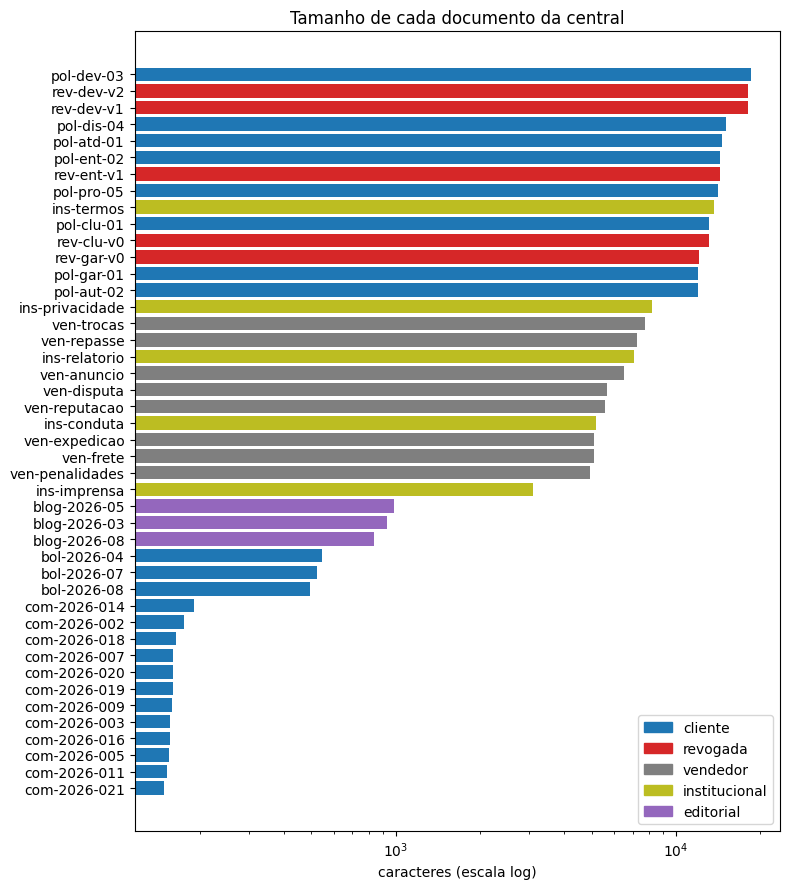

In [17]:
# ========================== SUA VEZ ==========================
# Etapa 1.1
# Manifesto como tabela: quantos documentos por público e por estrutura? Qual o tamanho de cada documento?
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)

# Manifesto como tabela, com o tamanho (em caracteres) de cada documento
man = pd.DataFrame(manifest).T
man.index.name = "doc"
man["chars"] = [len(DOCS[k]) for k in man.index]

print("Documentos por público x estrutura")
display(pd.crosstab(man["publico"], man["estrutura"], margins=True))

resumo = man.groupby("publico")["chars"].agg(qtd="count", minimo="min", mediana="median", maximo="max", total="sum")
resumo["% dos caracteres"] = (100 * resumo["total"] / resumo["total"].sum()).round(1)
print("\nTamanho (caracteres) por público")
display(resumo.sort_values("total", ascending=False))

# Tamanho de cada documento, em escala logarítmica, colorido por público
cores = {"cliente": "#1f77b4", "revogada": "#d62728", "vendedor": "#7f7f7f", "institucional": "#bcbd22", "editorial": "#9467bd"}
ordem = man.sort_values("chars")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(ordem.index, ordem["chars"], color=[cores[p] for p in ordem["publico"]])
ax.set_xscale("log")
ax.set_xlabel("caracteres (escala log)")
ax.set_title("Tamanho de cada documento da central")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()], labels=list(cores), loc="lower right")
plt.tight_layout()
plt.show()


Formatos de vigência no manifesto


publico,cliente,editorial,institucional,revogada,vendedor,All
vig_formato,,,,,,
início/ (aberta),21,0,0,0,0,21
início/9999-12-31 (aberta disfarçada),1,0,0,0,0,1
início/fim,1,0,0,5,0,6
vazia,0,3,5,0,8,16
All,23,3,5,5,8,44



Documentos cuja vigência foge do padrão:


,titulo,vigencia
doc,,
pol-dev-03,"Política de trocas, devoluções e ressarcimento (POL DEV 03, versão 3)",2026-07-01/9999-12-31


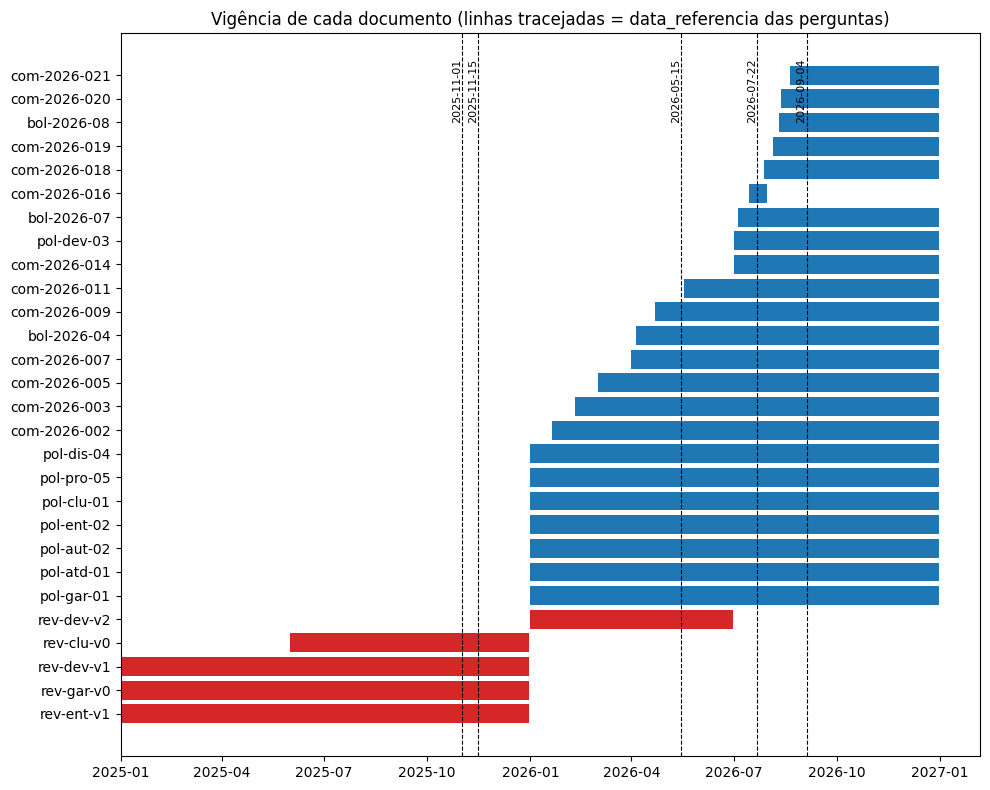

Políticas e versões vigentes em cada data de referência (pol-* e rev-*)
  2025-11-01: ['rev-gar-v0', 'rev-ent-v1', 'rev-dev-v1', 'rev-clu-v0']
  2025-11-15: ['rev-gar-v0', 'rev-ent-v1', 'rev-dev-v1', 'rev-clu-v0']
  2026-05-15: ['pol-atd-01', 'pol-ent-02', 'pol-clu-01', 'pol-pro-05', 'pol-aut-02', 'pol-dis-04', 'pol-gar-01', 'rev-dev-v2']
  2026-07-22: ['pol-atd-01', 'pol-dev-03', 'pol-ent-02', 'pol-clu-01', 'pol-pro-05', 'pol-aut-02', 'pol-dis-04', 'pol-gar-01']
  2026-09-04: ['pol-atd-01', 'pol-dev-03', 'pol-ent-02', 'pol-clu-01', 'pol-pro-05', 'pol-aut-02', 'pol-dis-04', 'pol-gar-01']

Total de documentos vigentes por data (inclui comunicados, boletins e docs sem vigência):
{'2025-11-01': 20, '2025-11-15': 20, '2026-05-15': 30, '2026-07-22': 34, '2026-09-04': 38}
Cabeçalho do texto x manifesto
  pol-atd-01  manifesto=2026-01-01/              cabeçalho=[]
  pol-dev-03  manifesto=2026-07-01/9999-12-31    cabeçalho=['Vigente a partir de 01/07/2026']
  pol-ent-02  manifesto=2026-01-01/ 

In [18]:
# ========================== SUA VEZ ==========================
# Etapa 1.2
# Linha do tempo das vigências: quais documentos valiam em cada data? Há formatos inconsistentes?
# Etapa 1.2: vigências do manifesto, normalizadas
def parse_vigencia(v):
    """Devolve (início, fim, formato). Fim aberto = NaT."""
    if not v:
        return pd.NaT, pd.NaT, "vazia"
    ini, fim = v.split("/")
    if fim == "":
        return pd.Timestamp(ini), pd.NaT, "início/ (aberta)"
    if fim.startswith("9999"):
        return pd.Timestamp(ini), pd.NaT, "início/9999-12-31 (aberta disfarçada)"
    return pd.Timestamp(ini), pd.Timestamp(fim), "início/fim"

man[["vig_ini", "vig_fim", "vig_formato"]] = [parse_vigencia(v) for v in man["vigencia"]]

print("Formatos de vigência no manifesto")
display(pd.crosstab(man["vig_formato"], man["publico"], margins=True))
print("\nDocumentos cuja vigência foge do padrão:")
display(man[man["vig_formato"].isin(["início/9999-12-31 (aberta disfarçada)"])][["titulo", "vigencia"]])

# Linha do tempo (só documentos com vigência definida)
DATAS_REF = sorted({p["data_referencia"] for p in perguntas})
FIM_GRAFICO = pd.Timestamp("2026-12-31")
t = man[man["vig_ini"].notna()].sort_values("vig_ini")
fig, ax = plt.subplots(figsize=(10, 8))
for i, (doc, r) in enumerate(t.iterrows()):
    fim = r["vig_fim"] if pd.notna(r["vig_fim"]) else FIM_GRAFICO
    ax.barh(i, (fim - r["vig_ini"]).days, left=r["vig_ini"], color=cores[r["publico"]])
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t.index)
for d in DATAS_REF:
    ax.axvline(pd.Timestamp(d), color="black", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d), len(t) - 0.3, d, rotation=90, va="top", ha="right", fontsize=8)
ax.set_title("Vigência de cada documento (linhas tracejadas = data_referencia das perguntas)")
plt.tight_layout()
plt.show()

def vigente_em(doc, data):
    """Vazia = sem restrição de data (regra a registrar no plano)."""
    r = man.loc[doc]
    d = pd.Timestamp(data)
    if pd.isna(r["vig_ini"]):
        return True
    return r["vig_ini"] <= d and (pd.isna(r["vig_fim"]) or d <= r["vig_fim"])

# Que políticas valiam em cada data de referência?
print("Políticas e versões vigentes em cada data de referência (pol-* e rev-*)")
for d in DATAS_REF:
    docs_ = [k for k in man.index if k.startswith(("pol-", "rev-")) and vigente_em(k, d)]
    print(f"  {d}: {docs_}")
print("\nTotal de documentos vigentes por data (inclui comunicados, boletins e docs sem vigência):")
print({d: sum(vigente_em(k, d) for k in man.index) for d in DATAS_REF})

# O texto diz a mesma coisa que o manifesto? Olhamos o cabeçalho (primeiros 600 caracteres)
# e a frase "Data de vigência" em qualquer ponto do documento.
cab = re.compile(r"(Vigente a partir de [\d/]+|vigente até [\d/]+|vigente de [\d/]+ a [\d/]+)", re.I)
dv = re.compile(r"Data de vigência[.:*\s]+([^\n]*)", re.I)
print("Cabeçalho do texto x manifesto")
for k in man.index:
    if k.startswith(("pol-", "rev-")):
        print(f"  {k:11s} manifesto={man.loc[k, 'vigencia']:24s} cabeçalho={cab.findall(DOCS[k][:600])}")
print("\nDocumentos cujo texto diz só 'Data de vigência: conforme publicação...':")
for k in man.index:
    m_ = dv.search(DOCS[k])
    if m_ and not re.search(r"\d", m_.group(1)):
        print(f"  {k:11s} {m_.group(1)[:70]}")


In [19]:
# ========================== SUA VEZ ==========================
# Etapa 1.3
# Mapa resposta → documento: em quais documentos aparece a resposta_referencia de cada pergunta?
# Etapa 1.3: mapa resposta → documento
def linhas_de_tabela(texto):
    return [l for l in texto.splitlines() if l.lstrip().startswith("|")]

linhas = []
for p in perguntas:
    resp = p["resposta_referencia"].lower()
    em = [k for k in DOCS if resp in DOCS[k].lower()]
    validos = [k for k in em if man.loc[k, "publico"] in ("cliente", "revogada") and vigente_em(k, p["data_referencia"])]
    ruido = [k for k in em if k not in validos]
    # onde a resposta aparece nos documentos válidos: em linha de tabela, em prosa, ou nos dois
    na_tabela = any(resp in l.lower() for k in validos for l in linhas_de_tabela(DOCS[k]))
    na_prosa = any(resp in l.lower() for k in validos for l in DOCS[k].splitlines() if not l.lstrip().startswith("|"))
    onde = "tabela+prosa" if na_tabela and na_prosa else "só tabela" if na_tabela else "só prosa"
    linhas.append({
        "id": p["id"], "data_ref": p["data_referencia"], "resposta": p["resposta_referencia"],
        "n_docs": len(em), "validos": validos, "so_ruido": len(validos) == 0,
        "so_revogado": bool(validos) and all(man.loc[k, "publico"] == "revogada" for k in validos),
        "so_com_bol": bool(validos) and all(k.startswith(("com-", "bol-")) for k in validos),
        "onde": onde, "docs_ruido": ruido,
    })
mapa = pd.DataFrame(linhas).set_index("id")

print("Perguntas por tipo de dependência (uma pergunta pode estar em mais de um grupo)")
print("  resposta não aparece em nenhum doc vigente de cliente/revogada:", int(mapa["so_ruido"].sum()))
print("  só em documento revogado (pergunta histórica):", int(mapa["so_revogado"].sum()), list(mapa.index[mapa["so_revogado"]]))
print("  só em comunicado ou boletim:", int(mapa["so_com_bol"].sum()), list(mapa.index[mapa["so_com_bol"]]))
print("  onde a resposta aparece nos docs válidos:", mapa["onde"].value_counts().to_dict())
print("  só em linha de tabela:", list(mapa.index[mapa["onde"] == "só tabela"]))
print("  resposta única (1 só documento no total):", int((mapa["n_docs"] == 1).sum()))
print("  resposta repetida em ≥ 5 documentos (risco de falso acerto):", int((mapa["n_docs"] >= 5).sum()), list(mapa.index[mapa["n_docs"] >= 5]))
print("  resposta que também aparece em doc de vendedor/institucional/editorial:",
      int(mapa["docs_ruido"].apply(lambda l: any(man.loc[k, "publico"] in ("vendedor", "institucional", "editorial") for k in l)).sum()))

print("\nMapa completo")
display(mapa[["data_ref", "resposta", "n_docs", "onde", "validos", "docs_ruido"]])


Perguntas por tipo de dependência (uma pergunta pode estar em mais de um grupo)
  resposta não aparece em nenhum doc vigente de cliente/revogada: 0
  só em documento revogado (pergunta histórica): 5 ['q19', 'q22', 'q47', 'q48', 'q49']
  só em comunicado ou boletim: 8 ['q21', 'q23', 'q55', 'q56', 'q57', 'q58', 'q59', 'q61']
  onde a resposta aparece nos docs válidos: {'só prosa': 31, 'tabela+prosa': 30, 'só tabela': 1}
  só em linha de tabela: ['q48']
  resposta única (1 só documento no total): 26
  resposta repetida em ≥ 5 documentos (risco de falso acerto): 11 ['q01', 'q02', 'q04', 'q09', 'q12', 'q20', 'q26', 'q35', 'q36', 'q54', 'q60']
  resposta que também aparece em doc de vendedor/institucional/editorial: 12

Mapa completo


,data_ref,resposta,n_docs,onde,validos,docs_ruido
id,,,,,,
q01,2026-09-04,retido,7,tabela+prosa,"[pol-atd-01, pol-ent-02, pol-dis-04]","[ven-repasse, ven-penalidades, rev-ent-v1, ins-privacidade]"
q02,2026-09-04,5 dias úteis,5,tabela+prosa,"[pol-dev-03, pol-ent-02, pol-aut-02]","[rev-dev-v2, rev-ent-v1]"
q03,2026-09-04,7 dias corridos,2,tabela+prosa,"[pol-dev-03, pol-gar-01]",[]
q04,2026-09-04,aceite expresso,5,só prosa,"[pol-dev-03, com-2026-019, bol-2026-08]","[rev-dev-v2, rev-dev-v1]"
q05,2026-09-04,3 dias úteis,2,tabela+prosa,"[pol-atd-01, pol-dis-04]",[]
q06,2026-09-04,cobrança é cancelada,3,só prosa,[pol-dev-03],"[rev-dev-v2, rev-dev-v1]"
q07,2026-09-04,7 dias corridos,2,tabela+prosa,"[pol-dev-03, pol-gar-01]",[]
q08,2026-09-04,sem custo,4,só prosa,"[pol-dev-03, bol-2026-07]","[rev-dev-v2, rev-dev-v1]"
q09,2026-09-04,retido,7,tabela+prosa,"[pol-atd-01, pol-ent-02, pol-dis-04]","[ven-repasse, ven-penalidades, rev-ent-v1, ins-privacidade]"


In [20]:
# ========================== SUA VEZ ==========================
# Etapa 1.4
# Perguntas por data_referencia: quantas são históricas (data diferente de 2026-09-04)?
# Etapa 1.4: perguntas por data_referencia
DATA_ATUAL = "2026-09-04"
dfp = pd.DataFrame(perguntas)
dfp["historica"] = dfp["data_referencia"] != DATA_ATUAL

print(dfp["data_referencia"].value_counts().sort_index().to_string())
print(f"\nPerguntas históricas (data diferente de {DATA_ATUAL}): {int(dfp['historica'].sum())} de {len(dfp)}")

hist = dfp[dfp["historica"]].set_index("id")
hist["docs_vigentes_com_a_resposta"] = mapa.loc[hist.index, "validos"]
hist["tambem_aparece_em"] = mapa.loc[hist.index, "docs_ruido"]
display(hist[["pergunta", "data_referencia", "resposta_referencia", "docs_vigentes_com_a_resposta", "tambem_aparece_em"]])


data_referencia
2025-11-01     2
2025-11-15     1
2026-05-15     2
2026-07-22     1
2026-09-04    56

Perguntas históricas (data diferente de 2026-09-04): 6 de 62


,pergunta,data_referencia,resposta_referencia,docs_vigentes_com_a_resposta,tambem_aparece_em
id,,,,,
q19,"em maio de 2026, qual era o teto de reembolso do plano padrão?",2026-05-15,"R$ 2.000,00",[rev-dev-v2],[com-2026-014]
q21,um pedido feito em 22/07/2026 para capital tinha qual prazo de ref...,2026-07-22,acrescidos de 2 dias úteis,[com-2026-016],[]
q22,qual era o prazo de garantia de brinquedo em novembro de 2025?,2025-11-01,30 dias,[rev-gar-v0],"[pol-gar-01, ven-repasse]"
q47,"em novembro de 2025, qual era o teto de reembolso do plano padrão?",2025-11-01,"R$ 1.500,00",[rev-dev-v1],[]
q48,"antes da versão 3 da política, qual era o prazo de reembolso acima...",2026-05-15,15 dias úteis,[rev-dev-v2],[rev-ent-v1]
q49,qual era o teto de reembolso do assinante em novembro de 2025?,2025-11-15,"R$ 5.000,00",[rev-clu-v0],[]


200 chamados, 200 ids únicos, 98 clientes distintos
Valores vazios por coluna: nenhum

classe
classe
artigo_proibido            30
falsificado                30
devolucao_ressarcimento    30
entrega                    30
fraude_vendedor            30
divergente_defeito         30
outros                     20

tipo_cliente
tipo_cliente
padrao     156
premium     44

categoria_produto
categoria_produto
game         50
outros       43
livro        37
maquiagem    36
brinquedo    34

tipo_vendedor
tipo_vendedor
vendedor        156
loja_oficial     44

Abertura de 2026-01-07 a 2026-10-20
Abertos antes de 2026-07-01 (vale a POL DEV 03 v2): 134
Abertos de 2026-07-01 em diante (vale a v3): 66
Abertos no recesso de 20 a 27/07 (com-2026-016): 8
Compra antes de 01/07 e abertura depois (caso de virada): 13
Dias entre compra e abertura: {'count': 200.0, 'mean': 25.4, 'std': 16.6, 'min': 2.0, '25%': 10.0, '50%': 23.0, '75%': 36.2, 'max': 60.0}

Faixas de preço (limites da POL DEV 03):
preco
até 100

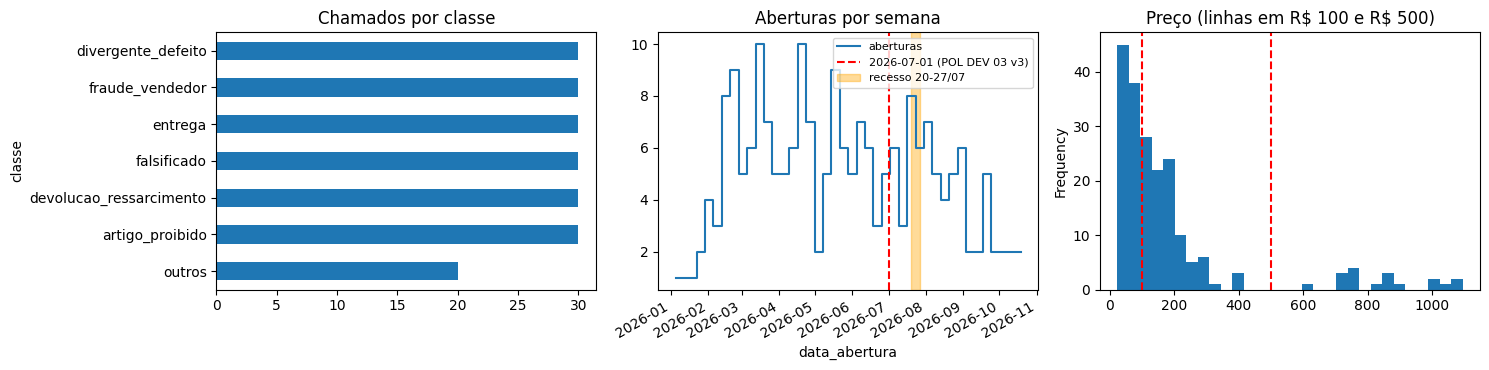

In [21]:
# ========================== SUA VEZ ==========================
# Etapa 1.5
# Chamados: distribuição de classe, tipo_cliente, categoria, datas de abertura, preços.
# Etapa 1.5: chamados
ch = pd.DataFrame(chamados)
ch["preco"] = ch["preco"].str.replace(",", ".").astype(float)
ch["avaliacao_produto"] = ch["avaliacao_produto"].str.replace(",", ".").astype(float)
for c in ["data_compra", "data_abertura"]:
    ch[c] = pd.to_datetime(ch[c])

print(f"{len(ch)} chamados, {ch['id_reclamacao'].nunique()} ids únicos, {ch['id_cliente'].nunique()} clientes distintos")
print("Valores vazios por coluna:", ch.isna().sum()[ch.isna().sum() > 0].to_dict() or "nenhum")
for col in ["classe", "tipo_cliente", "categoria_produto", "tipo_vendedor"]:
    print(f"\n{col}")
    print(ch[col].value_counts().to_string())

# Datas de corte
CORTE = pd.Timestamp("2026-07-01")
RECESSO = (pd.Timestamp("2026-07-20"), pd.Timestamp("2026-07-27"))
antes = ch["data_abertura"] < CORTE
recesso = ch["data_abertura"].between(*RECESSO)
virada = (ch["data_compra"] < CORTE) & ~antes
print(f"\nAbertura de {ch['data_abertura'].min().date()} a {ch['data_abertura'].max().date()}")
print(f"Abertos antes de 2026-07-01 (vale a POL DEV 03 v2): {int(antes.sum())}")
print(f"Abertos de 2026-07-01 em diante (vale a v3): {int((~antes).sum())}")
print(f"Abertos no recesso de 20 a 27/07 (com-2026-016): {int(recesso.sum())}")
print(f"Compra antes de 01/07 e abertura depois (caso de virada): {int(virada.sum())}")
print("Dias entre compra e abertura:", ch.assign(d=(ch['data_abertura'] - ch['data_compra']).dt.days)["d"].describe().round(1).to_dict())

# Preços
faixas = pd.cut(ch["preco"], [0, 100, 500, 2000, float("inf")], labels=["até 100", "100 a 500", "500 a 2000", "acima de 2000"], right=True)
print("\nFaixas de preço (limites da POL DEV 03):")
print(faixas.value_counts().sort_index().to_string())
print(f"Preço: mínimo {ch['preco'].min():.2f}, mediana {ch['preco'].median():.2f}, máximo {ch['preco'].max():.2f}")
print("Preço por categoria de produto (mediana):", ch.groupby("categoria_produto")["preco"].median().round(2).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ch["classe"].value_counts().sort_values().plot.barh(ax=ax[0], color="#1f77b4")
ax[0].set_title("Chamados por classe")
ch["data_abertura"].dt.to_period("W").dt.start_time.value_counts().sort_index().plot(ax=ax[1], drawstyle="steps-mid", color="#1f77b4", label="aberturas")
ax[1].axvline(CORTE, color="red", ls="--", label="2026-07-01 (POL DEV 03 v3)")
ax[1].axvspan(*RECESSO, color="orange", alpha=0.4, label="recesso 20-27/07")
ax[1].set_title("Aberturas por semana"); ax[1].legend(fontsize=8)
ch["preco"].plot.hist(bins=30, ax=ax[2], color="#1f77b4")
for lim in (100, 500):
    ax[2].axvline(lim, color="red", ls="--")
ax[2].set_title(r"Preço (linhas em R\$ 100 e R\$ 500)")
plt.tight_layout()
plt.show()


In [22]:
# ========================== SUA VEZ ==========================
# Etapa 1.5 (continuação)
# Classe do classificador x categoria informada pelo cliente; tags_sistema.
# Etapa 1.5 (continuação): classe do classificador x categoria informada pelo cliente, e tags
print("Classe (linhas) x categoria_informada_cliente (colunas)")
display(pd.crosstab(ch["classe"], ch["categoria_informada_cliente"], margins=True))

concorda = ch["classe"] == ch["categoria_informada_cliente"]
print(f"\nCliente e classificador concordam em {int(concorda.sum())} de {len(ch)} chamados ({concorda.mean():.0%}). Divergem em {int((~concorda).sum())}.")
print("Concordância por classe:", concorda.groupby(ch["classe"]).mean().round(2).to_dict())

# tags_sistema: o critério é desconhecido. Elas dizem alguma coisa sobre a classe?
tags = ch.assign(tag=ch["tags_sistema"].str.split("|")).explode("tag")
print("\nFrequência das tags:")
print(tags["tag"].value_counts().to_string())
print("\nTags por chamado:", ch["tags_sistema"].str.count(r"\|").add(1).value_counts().sort_index().to_dict())
tag_x_classe = pd.crosstab(tags["tag"], tags["classe"], normalize="index").round(2)
print("\nComposição de classes dentro de cada tag (se a tag informasse a classe, uma coluna dominaria):")
display(tag_x_classe)
print("Participação de cada classe no total, para comparar:", (ch["classe"].value_counts(normalize=True).round(2)).to_dict())


Classe (linhas) x categoria_informada_cliente (colunas)


categoria_informada_cliente,artigo_proibido,devolucao_ressarcimento,divergente_defeito,entrega,falsificado,fraude_vendedor,outros,All
classe,,,,,,,,
artigo_proibido,20,0,0,0,6,0,4,30
devolucao_ressarcimento,0,20,6,4,0,0,0,30
divergente_defeito,0,7,20,0,0,3,0,30
entrega,0,7,0,20,0,3,0,30
falsificado,0,0,5,0,20,5,0,30
fraude_vendedor,0,0,4,6,0,20,0,30
outros,0,0,5,2,0,0,13,20
All,20,34,40,32,26,31,17,200



Cliente e classificador concordam em 133 de 200 chamados (66%). Divergem em 67.
Concordância por classe: {'artigo_proibido': 0.67, 'devolucao_ressarcimento': 0.67, 'divergente_defeito': 0.67, 'entrega': 0.67, 'falsificado': 0.67, 'fraude_vendedor': 0.67, 'outros': 0.65}

Frequência das tags:
tag
pedido         78
compra         76
urgente        75
problema       73
atendimento    69
ajuda          68
produto        65
garantia       24
frete          22
pagamento      21
anuncio        21
cadastro       17
reembolso      15
devolucao      10

Tags por chamado: {2: 31, 3: 104, 4: 65}

Composição de classes dentro de cada tag (se a tag informasse a classe, uma coluna dominaria):


classe,artigo_proibido,devolucao_ressarcimento,divergente_defeito,entrega,falsificado,fraude_vendedor,outros
tag,,,,,,,
ajuda,0.12,0.18,0.16,0.15,0.13,0.15,0.12
anuncio,0.10,0.24,0.14,0.14,0.10,0.24,0.05
atendimento,0.12,0.14,0.20,0.13,0.22,0.12,0.07
cadastro,0.18,0.18,0.12,0.12,0.29,0.12,0.00
compra,0.20,0.12,0.13,0.17,0.14,0.13,0.11
devolucao,0.20,0.20,0.30,0.10,0.20,0.00,0.00
frete,0.18,0.05,0.23,0.14,0.09,0.23,0.09
garantia,0.12,0.17,0.08,0.17,0.08,0.12,0.25
pagamento,0.10,0.19,0.14,0.24,0.14,0.05,0.14


Participação de cada classe no total, para comparar: {'artigo_proibido': 0.15, 'falsificado': 0.15, 'devolucao_ressarcimento': 0.15, 'entrega': 0.15, 'fraude_vendedor': 0.15, 'divergente_defeito': 0.15, 'outros': 0.1}


In [23]:
# ========================== SUA VEZ ==========================
# Etapa 1.6
# Hipótese: cliente premium = assinante do Clube Q+?
# Etapa 1.6: hipótese "cliente premium = assinante do Clube Q+"
import re
termos = r"clube|q\+|assinante|assinatura|premium|prioritár"
ch["cita_clube"] = ch["texto_reclamacao"].str.contains(termos, case=False, regex=True)
print("Chamados por tipo de cliente")
print(ch["tipo_cliente"].value_counts().to_string())
print("\nChamados cujo texto cita Clube/assinante/premium, por tipo de cliente")
display(pd.crosstab(ch["tipo_cliente"], ch["cita_clube"]))
print("\nExemplos de premium:")
for t in ch[(ch["tipo_cliente"] == "premium") & ch["cita_clube"]]["texto_reclamacao"].head(3):
    print("  -", t[:230])
print("\nClasses dos chamados premium vs padrão (proporção):")
display(pd.crosstab(ch["tipo_cliente"], ch["classe"], normalize="index").round(2))

print("\nO que a base diz sobre o Clube Q+ e sobre 'premium':")
print("  documentos que mencionam 'premium':", [k for k in DOCS if "premium" in DOCS[k].lower()])
print("  documentos que mencionam 'Clube Q+':", [k for k in DOCS if "clube q+" in DOCS[k].lower()])
for linha in DOCS["pol-clu-01"].splitlines():
    if re.search(r"assinante|prioridade|prioritária|R\$ 8\.000|metade dos prazos|plano", linha, re.I) and len(linha) < 300:
        print("  POL CLU 01:", linha.strip()[:220])


Chamados por tipo de cliente
tipo_cliente
padrao     156
premium     44

Chamados cujo texto cita Clube/assinante/premium, por tipo de cliente


cita_clube,False
tipo_cliente,
padrao,156
premium,44



Exemplos de premium:

Classes dos chamados premium vs padrão (proporção):


classe,artigo_proibido,devolucao_ressarcimento,divergente_defeito,entrega,falsificado,fraude_vendedor,outros
tipo_cliente,,,,,,,
padrao,0.15,0.15,0.15,0.13,0.14,0.15,0.12
premium,0.14,0.16,0.14,0.20,0.18,0.16,0.02



O que a base diz sobre o Clube Q+ e sobre 'premium':
  documentos que mencionam 'premium': []
  documentos que mencionam 'Clube Q+': ['pol-dev-03', 'pol-clu-01', 'com-2026-007', 'bol-2026-04', 'rev-dev-v2', 'rev-dev-v1', 'rev-clu-v0']
  POL CLU 01: No cancelamento da assinatura, as condições de reembolso do assinante permanecem válidas até o fim do ciclo vigente já pago.
  POL CLU 01: **Assinante** é o usuário, pessoa física ou jurídica, que contratou e mantém ativa a assinatura do Clube Q+, estando em dia com todas as obrigações decorrentes do plano contratado.
  POL CLU 01: **Produto elegível** é qualquer item comercializado na plataforma que esteja devidamente sinalizado como apto a receber os benefícios do programa, conforme critérios definidos e periodicamente revisados pela equipe de op
  POL CLU 01: **Chamado** é qualquer solicitação formal registrada pelo assinante nos canais oficiais de atendimento da plataforma, sendo desconsideradas para fins desta política as manifestações

In [24]:
# ========================== SUA VEZ ==========================
# Etapa 1.7
# Os chamados da classe 'outros' têm cobertura na base? (duplicidade, nota fiscal, bivolt, boleto...)
# Etapa 1.7: os chamados 'outros' têm cobertura na base?
outros = ch[ch["classe"] == "outros"]
print(f"{len(outros)} chamados da classe 'outros'. Distribuição das categorias que o cliente informou:")
print(outros["categoria_informada_cliente"].value_counts().to_dict())

# tema do chamado (regex no texto)  ->  termos buscados na base
temas = {
    "cobrança em duplicidade":   (r"duplicidade|dois lançamentos",              r"duplicidade|cobrança duplicada|cobrado duas vezes|lançamento duplicado"),
    "nota fiscal / segunda via": (r"nota fiscal",                               r"nota fiscal|segunda via"),
    "bivolt / voltagem":         (r"bivolt",                                    r"bivolt|voltagem|110 ?v|220 ?v"),
    "trocar boleto por cartão":  (r"boleto",                                    r"boleto|alterar a forma de pagamento|trocar a forma de pagamento"),
    "cupom de primeira compra":  (r"cupom|desconto de primeira compra",         r"cupom de primeira compra|desconto de primeira|primeira compra"),
    "garantia estendida da loja":(r"garantia estendida",                        r"garantia estendida|plano de garantia"),
    "acesso à conta / código":   (r"acessar minha conta|código de verificação", r"acesso à conta|código de verificação|recuperar (a )?conta|redefinir (a )?senha"),
    "cancelar pedido por engano":(r"por erro|sem intenção",                     r"cancelar (o )?pedido|cancelamento do pedido|botão de cancelamento"),
    "alterar endereço":          (r"endereço de entrega",                       r"alterar (o )?endereço|atualizar (o )?endereço|mudança de endereço|endereço de entrega"),
    "juros no parcelamento":     (r"juros",                                     r"parcelamento|sem juros|juros"),
}
linhas = []
for tema, (rx_chamado, rx_base) in temas.items():
    n = int(outros["texto_reclamacao"].str.contains(rx_chamado, case=False, regex=True).sum())
    por_pub = {}
    for k in DOCS:
        achou = len(re.findall(rx_base, DOCS[k], flags=re.I))
        if achou:
            por_pub.setdefault(man.loc[k, "publico"], []).append(f"{k}({achou})")
    linhas.append({"tema": tema, "chamados 'outros'": n, "base cliente/revogada": por_pub.get("cliente", []) + por_pub.get("revogada", []),
                   "só vendedor/inst./editorial": sum([por_pub.get(p, []) for p in ("vendedor", "institucional", "editorial")], [])})
cobertura = pd.DataFrame(linhas).set_index("tema")
pd.set_option("display.max_colwidth", 90)
display(cobertura)
print("Soma dos chamados por tema:", int(cobertura["chamados 'outros'"].sum()), "(um chamado pode cair em dois temas; 'outros' tem 20)")

# Os temas que casaram na base de cliente: o trecho encontrado responde ao chamado, ou só usa a mesma palavra?
print("\nTrechos da base de cliente/revogada que casam com os temas (até 2 por tema):")
for tema, (_, rx_base) in temas.items():
    n = 0
    for k in DOCS:
        if man.loc[k, "publico"] in ("cliente", "revogada") and n < 2:
            for l in DOCS[k].splitlines():
                if re.search(rx_base, l, flags=re.I):
                    print(f"  [{tema}] {k}: {l.strip()[:170]}")
                    n += 1
                    break


20 chamados da classe 'outros'. Distribuição das categorias que o cliente informou:
{'outros': 13, 'divergente_defeito': 5, 'entrega': 2}


,chamados 'outros',base cliente/revogada,só vendedor/inst./editorial
tema,,,
cobrança em duplicidade,2,[],[]
nota fiscal / segunda via,2,"[pol-dev-03(1), pol-pro-05(1), rev-dev-v2(1), rev-dev-v1(1)]","[ven-disputa(4), blog-2026-05(1)]"
bivolt / voltagem,2,[],[]
trocar boleto por cartão,2,[],[]
cupom de primeira compra,2,[],[]
garantia estendida da loja,2,[],[]
acesso à conta / código,2,[pol-dis-04(1)],[]
cancelar pedido por engano,2,[],[]
alterar endereço,2,[],[]


Soma dos chamados por tema: 20 (um chamado pode cair em dois temas; 'outros' tem 20)

Trechos da base de cliente/revogada que casam com os temas (até 2 por tema):
  [nota fiscal / segunda via] pol-dev-03: Para compras acima de R$ 500,00, a análise documental pode incluir a apresentação dos seguintes documentos. - Nota fiscal do produto
  [nota fiscal / segunda via] pol-pro-05: 3.6.2. A ausência de nota fiscal de origem ou de documentação que comprove a cadeia de fornecimento é suficiente para o enquadramento na vedação de procedência não compro
  [acesso à conta / código] pol-dis-04: Caso a área de prevenção identifique indícios de uso indevido do mecanismo de disputas pelo cliente, a plataforma pode encerrar o chamado e adotar as medidas cabíveis, in


**O que a exploração mostrou.**

1. **A central tem mais ruído do que parece (célula 1.1).** Dos 44 documentos, só 23 são de público `cliente` (41,8% dos caracteres). Os 16 de vendedor, institucional e editorial somam 31,4% dos caracteres e não deveriam responder a um cliente. Os 5 revogados somam 26,9% e, ao contrário dos anteriores, **precisam ficar** (achado 3).
2. **Os documentos têm tamanhos muito diferentes (1.1).** A mediana dos documentos de cliente é 190 caracteres (os comunicados, de 149 em diante), enquanto as políticas chegam a 18 mil. Um chunk de tamanho fixo ou engole um comunicado inteiro junto com o vizinho, ou corta uma política no meio de uma tabela.
3. **Só 6 das 62 perguntas são históricas, e cinco delas dependem de documento revogado (1.3 e 1.4).** q19, q22, q47, q48 e q49 só têm a resposta vigente em `rev-*`. A q21 depende de um comunicado que valeu de 15 a 31/07 (`com-2026-016`). Em cada data de referência há uma única versão de cada política em vigor (1.2). Apagar os revogados custaria 5 perguntas.
4. **O manifesto é a fonte confiável de vigência; o texto não é (1.2).** 16 documentos não têm vigência no manifesto (vendedor, institucional, editorial). `pol-dev-03` usa fim `9999-12-31` onde as outras usam fim vazio. **`rev-dev-v1` e também `rev-dev-v2`** trazem no cabeçalho a frase copiada da v3 ("Vigente a partir de 01/07/2026"), e vários documentos dizem só "conforme publicação oficial". Quem ler o texto se confunde, então a vigência vai para o cabeçalho do chunk, vinda do manifesto.
5. **A métrica de recuperação é fácil de acertar por sorte (1.3).** 26 respostas aparecem em um único documento, mas 11 aparecem em 5 ou mais ("retido", "5 dias úteis", "conformidade"), e 12 aparecem também em documento de vendedor, institucional ou editorial. Exemplo: o "30 dias" da q22 (brinquedo, 2025) também está na linha de **livro** da POL GAR 01 atual. Por isso o diagnóstico de fonte certa (Etapa 2) é necessário.
6. **8 perguntas só se respondem por comunicado ou boletim** (q21, q23, q55 a q59, q61), documentos de uma ou duas frases, o formato mais vulnerável ao chunk fixo (1.3).
7. **Os chamados estão equilibrados, e a vigência pesa (1.5).** 30 por classe e 20 `outros`. 134 dos 200 foram abertos antes de 01/07/2026, quando valia a v2 (teto padrão R$ 2.000,00); 8 caíram no recesso de 20 a 27/07; 13 tiveram compra antes e abertura depois da virada. O preço vai de R$ 24,09 a R$ 1.095,03 (89 até R$ 100, 93 de R$ 100 a R$ 500, 18 acima de R$ 500), então a faixa do preço, a categoria e a data decidem o parâmetro correto e precisam estar na consulta.
8. **A categoria informada pelo cliente é ruído e as tags também (1.5).** Cliente e classificador concordam em 133 de 200 chamados (66%), com a mesma taxa em todas as classes (65% a 67%). As 14 tags não indicam a classe (cada uma se distribui como o total). Vale a `classe` do classificador, e `tags_sistema` fica de fora.
9. **Premium = Clube Q+ não se confirma (1.6).** Nenhum dos 44 chamados premium cita Clube, assinante ou premium, e nenhum documento da base usa a palavra "premium". A POL CLU 01 fala em "assinante". Premium também não coincide com `loja_oficial` (só 14 dos 44). Tratamos a equivalência como **suposição**, a registrar se o prompt a usar.
10. **Os 20 chamados `outros` são 10 temas, dois chamados cada, e nenhum tem cobertura na base (1.7).** Duplicidade de cobrança, nota fiscal, bivolt, boleto para cartão, cupom de primeira compra, garantia estendida, acesso à conta, cancelar pedido por engano, alterar endereço e juros no parcelamento. Os poucos achados por palavra são falsos: "nota fiscal" aparece como prova de documentação na POL DEV 03 e "acesso à conta" como punição na POL DIS 04. É o teste natural da abstenção.

**Previsão para a linha de base.** Palpite de 40 a 50 acertos em 62, com boa parte dos acertos "de graça", nas perguntas de resposta repetida (q01, q02, q09, q12, q20, q26, q35, q54, q60). Devem errar, ou acertar pela fonte errada:
- **q47 e q49**, cuja resposta só existe em revogado: a recuperação pelo significado traz os trechos de teto da política atual, que têm texto muito parecido.
- **q19 e q48**, que competem com a v3 e com `com-2026-014`, e **q22**, que pode acertar pelo "30 dias" da linha de livro.
- **q21, q23, q55 a q59 e q61**, os comunicados e boletins de uma ou duas frases, diluídos dentro de um chunk grande.
- As respostas em linha de tabela (q12, q40, q41, q13, q14, q42, q46), se o chunk separar o cabeçalho da tabela das linhas.

Se a linha de base ignora a vigência (como a equipe anterior), o ganho esperado da configuração 1 está nas históricas; o da configuração 3, nos comunicados e nas tabelas. Conferiremos na seção 1.

## 0.7 Infraestrutura de avaliação (Etapa 2)

Ferramentas usadas por todas as configurações:
- estrutura padrão de chunk (texto + metadados);
- registro `RESULTADOS` de cada medição;
- `diagnostico`: em que posição veio o trecho certo, de qual documento, e se ele estava vigente na data;
- `compara`: perguntas ganhas e perdidas entre duas configurações;
- `inspeciona`: os trechos recuperados de uma pergunta, com documento, vigência e score;
- `painel`: tabela de progresso de todas as configurações medidas até agora.

**Métricas acompanhadas em todas as configurações (nenhuma chama o LLM):**

| Métrica | O que mede |
|---|---|
| Hit@k | a célula oficial: em quantas perguntas a resposta aparece nos k trechos |
| Hit@1, Hit@3 | o mesmo, olhando só os 1 ou 3 primeiros trechos |
| MRR | média de 1/posição do primeiro trecho certo (1º = 1; 2º = 0,5; fora = 0). Mostra se o trecho certo **subiu**, mesmo quando o Hit@k não muda |
| Fonte certa | acertos cujo trecho veio de documento vigente e de público cliente |

O RAGAS, que chama o LLM, fica na seção 3 e cobre todas as configurações de uma vez, na mesma amostra.

In [25]:
# ========================== SUA VEZ ==========================
# Etapa 2
# Estrutura de chunk, RESULTADOS, mede/diagnostico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), compara, inspeciona, painel, matriz.
# Ferramentas de avaliação, usadas por todas as configurações.
# Contrato: cada configuração define um recuperador DETALHADO  det(pergunta, data) -> lista de chunks (dicts, já ordenados,
# com a chave extra "score"). A função recupera(pergunta, data) exigida pela célula oficial é derivada dele.
import random

RESULTADOS = {}
PUBLICO_OK = ("cliente", "revogada")   # públicos que podem legitimamente responder a um cliente

def novo_chunk(texto, doc_id, secao="", n=0, **extra):
    """Estrutura padrão de chunk. Os metadados vêm do manifesto (a vigência normalizada da célula 1.2)."""
    r = man.loc[doc_id]
    c = {"texto": texto, "doc_id": doc_id, "titulo": r["titulo"], "publico": r["publico"], "estrutura": r["estrutura"],
         "vig_ini": r["vig_ini"], "vig_fim": r["vig_fim"], "secao": secao, "chunk_id": f"{doc_id}#{n}"}
    c.update(extra)
    return c

def recupera_de(det):
    """Transforma o recuperador detalhado na função que a célula de medição oficial espera: devolve só os textos."""
    def recupera(pergunta, data):
        return [c["texto"] for c in det(pergunta, data)]
    return recupera

def _contem(resposta, texto):
    return resposta.lower() in texto.lower()          # mesma regra da célula oficial

def fonte_certa(chunk, data):
    """O trecho vem de documento de público cliente (ou revogado) e vigente na data da pergunta?"""
    return chunk["publico"] in PUBLICO_OK and vigente_em(chunk["doc_id"], data)

def mede(nome, det, params=None):
    """Roda as 62 perguntas, guarda tudo em RESULTADOS[nome] e imprime o resumo."""
    linhas, recuperados = [], {}
    for p in perguntas:
        cs = det(p["pergunta"], p["data_referencia"])
        recuperados[p["id"]] = cs
        pos = next((i for i, c in enumerate(cs, 1) if _contem(p["resposta_referencia"], c["texto"])), None)
        certos = [c for c in cs if _contem(p["resposta_referencia"], c["texto"])]
        linhas.append({
            "id": p["id"], "acerto": pos is not None, "posicao": pos,
            "doc_do_acerto": cs[pos - 1]["doc_id"] if pos else None,
            "fonte_certa": any(fonte_certa(c, p["data_referencia"]) for c in certos),
            "docs_com_a_resposta": sorted({c["doc_id"] for c in certos}),
        })
    df = pd.DataFrame(linhas)
    n = len(df)
    m = {
        "k": max((len(v) for v in recuperados.values()), default=0),
        "Hit@1": int((df["posicao"] == 1).sum()),
        "Hit@3": int((df["posicao"] <= 3).sum()),
        "Hit@k": int(df["acerto"].sum()),
        "MRR": float((1 / df["posicao"]).fillna(0).mean()),
        "fonte certa": int(df["fonte_certa"].sum()),
    }
    RESULTADOS[nome] = {"acertos": m["Hit@k"], "erradas": list(df["id"][~df["acerto"]]), "params": params or {},
                        "metricas": m, "linhas": df, "recuperados": recuperados}
    print(f"{nome}. {m['Hit@k']} de {n} | Hit@1 {m['Hit@1']} | Hit@3 {m['Hit@3']} | MRR {m['MRR']:.3f} | fonte certa {m['fonte certa']} | k={m['k']}")
    return m

def diagnostico(nome, mostra_tabela=False):
    """Por que acertou ou errou: posição do trecho certo, documento de onde veio, e se a fonte era a certa."""
    r = RESULTADOS[nome]; df = r["linhas"]; m = r["metricas"]
    print(f"== {nome} ==  params: {r['params']}")
    print("  " + " | ".join(f"{k} {v:.3f}" if k == "MRR" else f"{k} {v}" for k, v in m.items()))
    falso = df[df["acerto"] & ~df["fonte_certa"]]
    print(f"  acertos de fonte errada (acerto por sorte): {len(falso)} {list(falso['id'])}")
    print(f"  erradas ({len(r['erradas'])}): {r['erradas']}")
    if mostra_tabela:
        display(df.set_index("id"))

def painel():
    """Tabela de todas as configurações medidas até agora."""
    t = pd.DataFrame({nome: {**r["metricas"], "MRR": round(r["metricas"]["MRR"], 3)} for nome, r in RESULTADOS.items()}).T
    t.index.name = "configuração"
    t = t[["k", "Hit@1", "Hit@3", "Hit@k", "MRR", "fonte certa"]]
    display(t.astype({c: int for c in t.columns if c != "MRR"}))

def compara(a, b):
    """Perguntas ganhas, perdidas e mantidas ao ir da configuração a para a b."""
    la = RESULTADOS[a]["linhas"].set_index("id"); lb = RESULTADOS[b]["linhas"].set_index("id")
    ganhas = list(la.index[~la["acerto"] & lb["acerto"]]); perdidas = list(la.index[la["acerto"] & ~lb["acerto"]])
    ambas = int((la["acerto"] & lb["acerto"]).sum()); nenhuma = int((~la["acerto"] & ~lb["acerto"]).sum())
    dm = RESULTADOS[b]["metricas"]["MRR"] - RESULTADOS[a]["metricas"]["MRR"]
    print(f"{a} -> {b}: ganhou {len(ganhas)} {ganhas} | perdeu {len(perdidas)} {perdidas} | acertam nas duas {ambas} | erram nas duas {nenhuma} | variação do MRR {dm:+.3f}")
    return ganhas, perdidas

def inspeciona(qid, nome, chars=170):
    """Os trechos recuperados de uma pergunta, com documento, vigência e score."""
    p = next(x for x in perguntas if x["id"] == qid)
    print(f"{qid} [{p['data_referencia']}] {p['pergunta']}\n  resposta esperada: {p['resposta_referencia']!r}  | config: {nome}")
    for i, c in enumerate(RESULTADOS[nome]["recuperados"][qid], 1):
        achou = "✔" if _contem(p["resposta_referencia"], c["texto"]) else " "
        vig = f"{c['vig_ini'].date() if pd.notna(c['vig_ini']) else '—'}/{c['vig_fim'].date() if pd.notna(c['vig_fim']) else ''}"
        ok = "vigente" if vigente_em(c["doc_id"], p["data_referencia"]) else "FORA da vigência"
        sc = f"{c['score']:.3f}" if c.get("score") is not None else "—"
        print(f"  {i:2d} {achou} {c['doc_id']:13s} {c['publico']:13s} {vig:23s} {ok:17s} score {sc} | {c['secao'][:25]:25s} | {c['texto'][:chars]!r}")

def matriz():
    """Pergunta x configuração (✔/✘), para a comparação final."""
    t = pd.DataFrame({nome: r["linhas"].set_index("id")["acerto"].map({True: "✔", False: "✘"}) for nome, r in RESULTADOS.items()})
    t.loc["TOTAL ✔"] = (t == "✔").sum()
    return t


**Como usar as ferramentas nas próximas seções.** Cada configuração escreve um recuperador detalhado `det(pergunta, data)` que devolve a lista de chunks (criados com `novo_chunk`, mais a chave `score`). Depois:

```python
recupera = recupera_de(det)        # a célula de medição oficial usa esta função
mede("configuração 1", det, {...}) # guarda tudo em RESULTADOS e imprime o resumo
diagnostico("configuração 1"); painel(); compara("linha de base", "configuração 1"); inspeciona("q47", "configuração 1")
```

**Fonte certa.** Um acerto conta como de fonte certa quando algum trecho que contém a resposta vem de documento de público `cliente` ou `revogada` e vigente na data da pergunta (regra de vigência da célula 1.2: vigência vazia = sem restrição de data). Revogada entra porque as perguntas históricas só se respondem por ela.

O teste abaixo usa recuperadores de mentira. O aleatório deve acertar quase nada. Os dois "oráculos" leem a resposta (trapaça, só para testar): ambos devem dar 62 de 62, mas só o que respeita a vigência dá 62 de fonte certa, e a diferença são os falsos acertos (q19 e q22).

In [26]:
# ========================== SUA VEZ ==========================
# Etapa 2. Teste das ferramentas
# Teste das ferramentas, com recuperadores de mentira. Nada aqui é a linha de base e tudo é apagado no fim.
rng = random.Random(SEED)
chunks_teste = [novo_chunk(DOCS[k][i:i + 1000], k, n=i // 1000) for k in DOCS for i in range(0, len(DOCS[k]), 1000)]

def det_aleatorio(pergunta, data, k=5):
    return [{**c, "score": None} for c in rng.sample(chunks_teste, k)]

def _docs_com(resposta):
    return [k for k in DOCS if resposta.lower() in DOCS[k].lower()]

def _por_pergunta(pergunta):
    return next(p for p in perguntas if p["pergunta"] == pergunta)

def det_oraculo_ingenuo(pergunta, data):    # trapaça: lê a resposta; pega o 1º documento que a contém, sem olhar vigência
    p = _por_pergunta(pergunta); ks = _docs_com(p["resposta_referencia"])[:1]
    return [{**novo_chunk(DOCS[k], k), "score": 1.0} for k in ks]

def det_oraculo_vigente(pergunta, data):    # trapaça: só documentos válidos na data, vigentes de cliente ou revogado
    p = _por_pergunta(pergunta)
    ks = [k for k in _docs_com(p["resposta_referencia"]) if man.loc[k, "publico"] in PUBLICO_OK and vigente_em(k, data)][:1]
    return [{**novo_chunk(DOCS[k], k), "score": 1.0} for k in ks]

mede("_aleatorio", det_aleatorio, {"k": 5})
mede("_oraculo_ingenuo", det_oraculo_ingenuo)
mede("_oraculo_vigente", det_oraculo_vigente)

# A célula oficial deve dar o mesmo número que `mede`, usando só recupera(pergunta, data)
recupera = recupera_de(det_oraculo_ingenuo)
oficial = sum(any(p["resposta_referencia"].lower() in t.lower() for t in recupera(p["pergunta"], p["data_referencia"])) for p in perguntas)
print("célula oficial:", oficial, "| mede:", RESULTADOS["_oraculo_ingenuo"]["acertos"])

painel()
compara("_oraculo_ingenuo", "_oraculo_vigente")
diagnostico("_oraculo_ingenuo")
inspeciona("q22", "_oraculo_ingenuo", chars=90)
display(matriz().iloc[[0, 1, 2, 3, -1]])

RESULTADOS.clear()   # as ferramentas ficam; os resultados de teste não


_aleatorio. 9 de 62 | Hit@1 3 | Hit@3 6 | MRR 0.080 | fonte certa 7 | k=5
_oraculo_ingenuo. 62 de 62 | Hit@1 62 | Hit@3 62 | MRR 1.000 | fonte certa 60 | k=1
_oraculo_vigente. 62 de 62 | Hit@1 62 | Hit@3 62 | MRR 1.000 | fonte certa 62 | k=1
célula oficial: 62 | mede: 62


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
_aleatorio,5,3,6,9,0.08,7
_oraculo_ingenuo,1,62,62,62,1.00,60
_oraculo_vigente,1,62,62,62,1.00,62


_oraculo_ingenuo -> _oraculo_vigente: ganhou 0 [] | perdeu 0 [] | acertam nas duas 62 | erram nas duas 0 | variação do MRR +0.000
== _oraculo_ingenuo ==  params: {}
  k 1 | Hit@1 62 | Hit@3 62 | Hit@k 62 | MRR 1.000 | fonte certa 60
  acertos de fonte errada (acerto por sorte): 2 ['q19', 'q22']
  erradas (0): []
q22 [2025-11-01] qual era o prazo de garantia de brinquedo em novembro de 2025?
  resposta esperada: '30 dias'  | config: _oraculo_ingenuo
   1 ✔ pol-gar-01    cliente       2026-01-01/             FORA da vigência  score 1.000 |                           | '# Tabela de garantia por categoria (POL GAR 01)\n\n## Preâmbulo e Apresentação do Instrument'


,_aleatorio,_oraculo_ingenuo,_oraculo_vigente
id,,,
q01,✔,✔,✔
q02,✘,✔,✔
q03,✔,✔,✔
q04,✘,✔,✔
TOTAL ✔,9,62,62


## 1. Linha de base

O assistente como a equipe anterior o construiu. Chunk de tamanho fixo sobre a central inteira, recuperação por similaridade e geração com os trechos no prompt. O prompt traz o papel do assistente, o escopo e a instrução de responder só com o que está nos trechos.

A medição da recuperação no conjunto de referência é a fração das 62 perguntas em que `resposta_referencia` aparece no texto dos trechos recuperados, com `data_referencia` como data de referência da vigência. A linha de base ignora a vigência, porque a equipe anterior a ignorava.

In [27]:
# ========================== SUA VEZ ==========================
# Indexação da linha de base. Chunk de tamanho fixo sobre todos os documentos, embedding e índice.
# Indexação da linha de base: como a equipe anterior fez.
# Chunk de tamanho fixo (800 caracteres, sobreposição de 100) sobre cada um dos 44 documentos,
# cortado onde cair (até no meio de uma palavra ou de uma tabela), sem metadados no texto.
TAM_CHUNK, SOBREPOSICAO = 800, 100

def chunk_fixo(texto, tam=TAM_CHUNK, sobrep=SOBREPOSICAO):
    passo = tam - sobrep
    return [texto[i:i + tam] for i in range(0, len(texto), passo) if texto[i:i + tam].strip()]

CHUNKS_BASE = [novo_chunk(t, doc_id, n=n) for doc_id in DOCS for n, t in enumerate(chunk_fixo(DOCS[doc_id]))]
print(f"{len(CHUNKS_BASE)} chunks de até {TAM_CHUNK} caracteres, de {len(DOCS)} documentos.")
print("Chunks por público:", pd.Series([c["publico"] for c in CHUNKS_BASE]).value_counts().to_dict())
print("Comprimento médio:", round(np.mean([len(c["texto"]) for c in CHUNKS_BASE])), "caracteres")

# Embeddings (cacheados em disco). Os das perguntas já ficam prontos para a medição.
E_BASE = embed([c["texto"] for c in CHUNKS_BASE], task="RETRIEVAL_DOCUMENT")
_ = embed([p["pergunta"] for p in perguntas], task="RETRIEVAL_QUERY")
print("Matriz de embeddings dos chunks:", E_BASE.shape)


428 chunks de até 800 caracteres, de 44 documentos.
Chunks por público: {'cliente': 182, 'revogada': 110, 'vendedor': 74, 'institucional': 56, 'editorial': 6}
Comprimento médio: 745 caracteres
Matriz de embeddings dos chunks: (428, 768)


In [28]:
# ========================== SUA VEZ ==========================
# Recuperação e geração. O prompt do assistente, com papel, escopo e a instrução de responder só com os trechos.
# Recuperação e geração da linha de base.
K_PROVISORIO = 5      # só para a Etapa 3; o TOP_K definitivo sai da seção 1.1 e vale para todas as configurações

def det_base(pergunta, data, k=None):
    """Similaridade por cosseno com a pergunta. O parâmetro `data` é recebido e NÃO é usado (a equipe anterior ignorava a vigência)."""
    k = k or TOP_K or K_PROVISORIO
    q = embed([pergunta], task="RETRIEVAL_QUERY")[0]
    scores = E_BASE @ q                        # vetores normalizados: produto escalar = cosseno
    melhores = np.argsort(-scores)[:k]
    return [{**CHUNKS_BASE[i], "score": float(scores[i])} for i in melhores]

recupera = recupera_de(det_base)               # a célula de medição oficial usa esta função

# Prompt da equipe anterior: papel, escopo e a instrução de responder só com os trechos. Nada além disso.
SYSTEM_BASE = ("Você é o assistente de atendimento da Quantum Commerce, um marketplace brasileiro. "
               "Você responde a dúvidas de clientes sobre as políticas da plataforma (devolução, garantia, entrega, "
               "Clube Q+, disputas e autenticidade). Responda somente com base nos trechos fornecidos.")

def gera_resposta_base(pergunta, trechos):
    contexto = "\n\n".join(f"[Trecho {i}]\n{t}" for i, t in enumerate(trechos, 1))
    msg = f"Trechos:\n{contexto}\n\nPergunta do cliente: {pergunta}"
    return get_llm_response([{"role": "user", "content": msg}], system=SYSTEM_BASE)

# Demonstração em uma pergunta
p = perguntas[2]
print("Pergunta:", p["pergunta"], "| esperado:", p["resposta_referencia"])
print("Resposta:", gera_resposta_base(p["pergunta"], recupera(p["pergunta"], p["data_referencia"])))


Pergunta: recebi o produto ontem e me arrependi da compra, tenho quantos dias para desistir? | esperado: 7 dias corridos
Resposta: Você tem o prazo de até 7 dias corridos, contados a partir da data de recebimento do produto, para exercer o seu direito de arrependimento e desistir da compra. 

Para isso, você precisa abrir um chamado na central de atendimento da plataforma dentro desse prazo, informando o número do pedido e a opção de desistência. Não é necessário apresentar justificativa e a desistência não gera nenhum ônus para você.


In [29]:
# Medição da recuperação no conjunto de referência. A variável `recupera(pergunta, data)` devolve a lista de trechos.
# Esta célula fica como está. Ela é a mesma para todas as configurações.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"linha de base. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

linha de base. 50 de 62
erradas. ['q12', 'q23', 'q25', 'q26', 'q37', 'q40', 'q41', 'q44', 'q48', 'q51', 'q53', 'q64']


In [30]:
# ========================== SUA VEZ ==========================
# Etapa 3. Diagnóstico
# Registro em RESULTADOS, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel()
# e inspeção de 2 ou 3 perguntas erradas.
# Etapa 3. Diagnóstico
mede("linha de base", det_base, {"chunk": f"fixo {TAM_CHUNK}/{SOBREPOSICAO}", "embedding": EMB_MODEL, "k": K_PROVISORIO, "usa_data": False})
diagnostico("linha de base")
painel()

# Como as erradas se agrupam (usa o mapa da célula 1.3)
r = RESULTADOS["linha de base"]
erradas = r["erradas"]
grupos = {
    "histórica (data ≠ 2026-09-04)": [q for q in erradas if dfp.set_index("id").loc[q, "historica"]],
    "só em comunicado/boletim": [q for q in erradas if mapa.loc[q, "so_com_bol"]],
    "resposta em tabela (tabela+prosa ou só tabela)": [q for q in erradas if mapa.loc[q, "onde"] != "só prosa"],
}
print("\nErradas por motivo provável (uma pergunta pode aparecer em mais de um grupo):")
for g, qs in grupos.items():
    print(f"  {g}: {len(qs)} {qs}")
print("  nenhum dos três:", [q for q in erradas if not any(q in qs for qs in grupos.values())])

# Acertos "sujos": a resposta veio, mas de fonte errada, ou o top-k trouxe documento que não deveria
df = r["linhas"].set_index("id")
print("\nAcertos de fonte errada:", list(df.index[df["acerto"] & ~df["fonte_certa"]]))
todos = [c for v in r["recuperados"].values() for c in v]
print("Trechos recuperados por público:", pd.Series([c["publico"] for c in todos]).value_counts().to_dict())
fora = sum(not vigente_em(c["doc_id"], p["data_referencia"]) for p in perguntas for c in r["recuperados"][p["id"]])
print(f"Trechos de documento fora da vigência na data da pergunta: {fora} de {len(todos)}")

# O trecho mais bem colocado é de documento vigente? (é o que o LLM mais pesa ao responder)
topo_fora = [p["id"] for p in perguntas if not vigente_em(r["recuperados"][p["id"]][0]["doc_id"], p["data_referencia"])]
topo_nao_cliente = [p["id"] for p in perguntas if r["recuperados"][p["id"]][0]["publico"] not in PUBLICO_OK]
print(f"1º trecho de documento fora da vigência: {len(topo_fora)} de {len(perguntas)}")
print(f"1º trecho de documento de vendedor, institucional ou editorial: {len(topo_nao_cliente)} de {len(perguntas)}")
atuais = [p["id"] for p in perguntas if p["data_referencia"] == DATA_ATUAL]
print(f"Das {len(atuais)} perguntas de 2026-09-04, em quantas há algum trecho revogado entre os {K_PROVISORIO}:",
      sum(any(c["publico"] == "revogada" for c in r["recuperados"][q]) for q in atuais))

# Previsão (markdown 'O que a exploração mostrou') x resultado
previstas = ["q47", "q49", "q19", "q48", "q22", "q21", "q23", "q55", "q56", "q57", "q58", "q59", "q61"]
print(f"\nPrevisão: {len(previstas)} perguntas deviam errar ou acertar pela fonte errada.")
print("  confirmadas (erraram):", [q for q in previstas if q in erradas])
print("  acertaram pela fonte errada:", [q for q in previstas if q not in erradas and not df.loc[q, 'fonte_certa']])
print("  acertaram de fonte certa (previsão errada):", [q for q in previstas if q not in erradas and df.loc[q, 'fonte_certa']])
print("  erraram sem estar na previsão:", [q for q in erradas if q not in previstas])


linha de base. 50 de 62 | Hit@1 32 | Hit@3 43 | MRR 0.618 | fonte certa 48 | k=5
== linha de base ==  params: {'chunk': 'fixo 800/100', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': False}
  k 5 | Hit@1 32 | Hit@3 43 | Hit@k 50 | MRR 0.618 | fonte certa 48
  acertos de fonte errada (acerto por sorte): 2 ['q01', 'q33']
  erradas (12): ['q12', 'q23', 'q25', 'q26', 'q37', 'q40', 'q41', 'q44', 'q48', 'q51', 'q53', 'q64']


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48



Erradas por motivo provável (uma pergunta pode aparecer em mais de um grupo):
  histórica (data ≠ 2026-09-04): 1 ['q48']
  só em comunicado/boletim: 1 ['q23']
  resposta em tabela (tabela+prosa ou só tabela): 7 ['q12', 'q25', 'q26', 'q40', 'q41', 'q48', 'q51']
  nenhum dos três: ['q37', 'q44', 'q53', 'q64']

Acertos de fonte errada: ['q01', 'q33']
Trechos recuperados por público: {'cliente': 171, 'revogada': 100, 'vendedor': 29, 'editorial': 7, 'institucional': 3}
Trechos de documento fora da vigência na data da pergunta: 117 de 310
1º trecho de documento fora da vigência: 20 de 62
1º trecho de documento de vendedor, institucional ou editorial: 7 de 62
Das 56 perguntas de 2026-09-04, em quantas há algum trecho revogado entre os 5: 38

Previsão: 13 perguntas deviam errar ou acertar pela fonte errada.
  confirmadas (erraram): ['q48', 'q23']
  acertaram pela fonte errada: []
  acertaram de fonte certa (previsão errada): ['q47', 'q49', 'q19', 'q22', 'q21', 'q55', 'q56', 'q57', 'q58', 'q59

In [31]:
# Etapa 3. Inspeção de perguntas erradas (uma de cada tipo, quando existir)
# Inspeção de erradas: uma de cada tipo, quando existir (histórica, comunicado/boletim, outra)
escolhidas = []
for g in list(grupos.values()) + [[q for q in erradas if not any(q in qs for qs in grupos.values())]]:
    for q in g:
        if q not in escolhidas:
            escolhidas.append(q); break
for q in escolhidas[:3]:
    inspeciona(q, "linha de base", chars=110)
    print()


q48 [2026-05-15] antes da versão 3 da política, qual era o prazo de reembolso acima de R$ 100?
  resposta esperada: '15 dias úteis'  | config: linha de base
   1   pol-dev-03    cliente       2026-07-01/             FORA da vigência  score 0.861 |                           | ' o prazo aplicável ao seu caso.\n\n**Posso alterar minha escolha entre troca e reembolso depois de abrir o chama'
   2   pol-clu-01    cliente       2026-01-01/             vigente           score 0.857 |                           | '. Esse limite se aplica por transação individual e não é cumulativo entre compras distintas realizadas no mesm'
   3   rev-dev-v1    revogada      2025-01-01/2025-12-31   FORA da vigência  score 0.853 |                           | '# Política de Trocas, Devoluções e Ressarcimento (POL DEV 03, versão 1)\n\nVersão 1, vigente até 31/12/2025. Sub'
   4   rev-clu-v0    revogada      2025-06-01/2025-12-31   FORA da vigência  score 0.852 |                           | ' não é cumulativo entre

In [ ]:
# Etapa 3. Por que as erradas erraram: onde está o trecho que contém a resposta no ranking completo e o que ocupou o top-k
r = RESULTADOS["linha de base"]
linhas = []
for q in r["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    scores = E_BASE @ embed([p["pergunta"]], task="RETRIEVAL_QUERY")[0]
    ordem = np.argsort(-scores)
    contem = [(i + 1, j) for i, j in enumerate(ordem) if p["resposta_referencia"].lower() in CHUNKS_BASE[j]["texto"].lower()]
    pos_qq, j_qq = contem[0]                                                   # 1º trecho que contém a string, de qualquer fonte
    pos, j = next((i, j) for i, j in contem if fonte_certa(CHUNKS_BASE[j], p["data_referencia"]))   # 1º de fonte certa
    melhor = CHUNKS_BASE[j]
    ls = melhor["texto"].splitlines()
    topo = r["recuperados"][q]
    def classe(c):
        if c["publico"] == "revogada": return "revogado"
        if c["publico"] != "cliente": return "outro público"
        return "cliente vigente" if vigente_em(c["doc_id"], p["data_referencia"]) else "cliente fora da vigência"
    comp = pd.Series([classe(c) for c in topo]).value_counts()
    linhas.append({
        "id": q, "pos (qualquer fonte)": pos_qq, "doc (qualquer fonte)": CHUNKS_BASE[j_qq]["doc_id"],
        "pos (fonte certa)": pos, "doc (fonte certa)": melhor["doc_id"],
        "score 1º - 5º": round(topo[0]["score"] - topo[-1]["score"], 3),
        "revogado": comp.get("revogado", 0), "cliente fora da vigência": comp.get("cliente fora da vigência", 0),
        "outro público": comp.get("outro público", 0), "cliente vigente": comp.get("cliente vigente", 0),
        "tabela no trecho de fonte certa": ("com cabeçalho" if any(l.lstrip().startswith("|--") or l.lstrip().startswith("| --") for l in ls)
                                   else "só linhas, sem cabeçalho" if any(l.lstrip().startswith("|") for l in ls) else "não"),
    })
diag_erradas = pd.DataFrame(linhas).set_index("id")
display(diag_erradas)
print("Spread médio do score entre o 1º e o 5º, nas 62 perguntas:",
      round(np.mean([v[0]["score"] - v[-1]["score"] for v in r["recuperados"].values()]), 3))


**Análise da linha de base.**

- **Resultado.** 50 de 62 com k = 5 provisório (o k definitivo sai na seção 1.1, e o número da linha de base será refeito e congelado com ele). Hit@1 32, Hit@3 43, MRR 0,618. Acertos de fonte certa: 48. Dois acertos são por sorte (q01 e q33: a string veio de documento errado). O 48 é um **teto**: a fonte certa confere público e vigência, não se o trecho responde à pergunta (na q12, por exemplo, o "5 dias úteis" de um documento vigente fala de autenticidade, não de reembolso).
- **O embedding importa.** Uma execução preliminar com o embedding do Gemini (depois trocado por causa do limite de cota, e que não está neste notebook) deu 56 de 62 e MRR 0,688. Com o mesmo chunk e o mesmo k, o `multilingual-e5-base` acerta 6 perguntas a menos. Por isso o embedding fica **fixo** daqui para a frente: só vale comparar configurações com o mesmo modelo.
- **A previsão da Etapa 1 acertou pouco.** Prevíamos erro ou fonte errada em 13 perguntas (históricas, comunicados e boletins). Só **2** erraram (q48, histórica, e q23, comunicado); as outras 11 acertaram de fonte certa, e 10 perguntas que erraram não estavam na previsão. Dois erros de raciocínio: (1) o chunk é cortado por documento, então cada comunicado vira um chunk inteiro e não é engolido por nada; (2) os documentos revogados continuam no índice, então 5 das 6 históricas acertam. Isso **não** significa que o sistema escolhe a versão certa: nas 56 perguntas de 2026-09-04, 38 também recebem trecho revogado entre os 5.
- **O Hit@k esconde o problema de vigência.** Dos 310 trechos recuperados, 117 (38%) são de documento fora da vigência na data da pergunta, e 100 (32%) são de documentos revogados (nas 6 históricas, alguns são legítimos). Em 20 das 62 perguntas o **primeiro** trecho está fora da vigência, e em 7 ele é de vendedor, institucional ou editorial. Como a v1, a v2 e a v3 da política de devolução têm textos quase iguais, as versões disputam o top-k: na q25 os cinco trechos são todos de documentos revogados.
- **Causas das 12 erradas (tabela da célula de diagnóstico).**
  - **Vigência:** em 11 das 12, pelo menos uma das 5 vagas está ocupada por trecho revogado ou fora da vigência. Só a q44 não tem.
  - **Público errado:** em 4 (q12, q23, q37, q44) há trecho de vendedor, institucional ou editorial no top-5; na q44, 4 dos 5. É o alvo da curadoria.
  - **Código literal:** a q23 pergunta por "COM 2026 019", e o top-5 traz outros comunicados de modelo parecido; o comunicado certo está na 9ª posição. É uma hipótese a testar na busca híbrida.
  - **Tabela, não confirmada.** Só q41 e q48 têm tabela no trecho de fonte certa, e nos dois o trecho traz o cabeçalho. Não observamos o corte do cabeçalho que o plano temia; fica como hipótese a verificar no chunking por estrutura.
- **Quão longe está o trecho certo.** O primeiro trecho de fonte certa fica entre as posições 6 e 16 em 8 das 12 erradas (q25, q23, q26, q64, q12, q48, q44, q41), perto do corte, e a partir da 28ª em 4 (q51, q53, q37, q40). Um k maior só ajudaria as primeiras, o que a seção 1.1 vai medir; as outras exigem mudar a busca. Os scores são muito próximos (diferença média de 0,017 entre o 1º e o 5º nas 62 perguntas, de 0,002 a 0,029 nas erradas), o que é típico do e5 e não distingue as erradas das certas; ainda assim, a ordem final é decidida por diferenças de milésimos.
- **Limite da métrica.** O Hit@k mede se a string aparece, e com k = 5 há espaço para subir até 62. O Hit@1 e o MRR mostram melhor o efeito de cada técnica.

**Decisão.** A primeira mudança é o **filtro de vigência** (configuração 1), porque é a causa presente em 11 das 12 erradas e porque 38% do contexto está fora da vigência. Esperamos mais Hit@1, MRR e acertos de fonte certa, e que os revogados saiam do top-k das perguntas atuais **sem perder as históricas**, que dependem de a data decidir qual versão vale. O filtro provavelmente não resolve as 4 erradas que estão a partir da 28ª posição (q51, q53, q37, q40). A q44 e o ruído de outro público ficam para a curadoria (configuração 2), e a q23, para a busca híbrida (configuração 4).

### 1.1 Escolha do top-k (Etapa 4)

O enunciado permite ajustar o top-k, mas exige o mesmo valor em todas as configurações comparadas. Varremos k na linha de base e fixamos `TOP_K`.

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 4
# Varredura de k em {3, 5, 8, 10}: acertos e tamanho médio do contexto. Fixar TOP_K.

**Análise do top-k.** [Onde o ganho satura, quanto contexto cada k custa, qual k foi escolhido e por quê.]

## 2. Melhorias, uma de cada vez

Cada configuração nova muda uma coisa em relação à anterior. A célula de medição é a mesma da seção 1. Repita o bloco abaixo (mudança, medição, análise) para cada configuração testada. Curadoria, chunking por tipo com metadados, filtro de vigência pela data, busca híbrida, re-ranking, parent-document retrieval e a classe do chamado como metadado são as técnicas da disciplina. A ordem e a escolha são do grupo.

### Configuração 1. Filtro de vigência

**O que muda em relação à anterior.** Antes da busca, manter só os trechos de documentos vigentes na data de referência.

**Hipótese e previsão.** [Escrever **antes** de rodar: que perguntas devem mudar, e por quê.]

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 1
# O que muda em relação à configuração anterior, e só isso.

In [ ]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 1. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 1. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.

**Análise da configuração 1.** [Hit@k e MRR contra a anterior. Que perguntas ganhou e que perguntas perdeu. A causa investigada. A decisão.]

### Configuração 2. Curadoria por público e de conteúdo

**O que muda em relação à anterior.** Retirar documentos de vendedor, institucionais e editoriais (mantendo os revogados) e corrigir problemas de conteúdo.

**Hipótese e previsão.** [Escrever **antes** de rodar: que perguntas devem mudar, e por quê.]

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 2
# O que muda em relação à configuração anterior, e só isso.

In [ ]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 2. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 2. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.

**Análise da configuração 2.** [Hit@k e MRR contra a anterior. Que perguntas ganhou e que perguntas perdeu. A causa investigada. A decisão.]

### Configuração 3. Chunking por estrutura com metadados

**O que muda em relação à anterior.** Cortar por seção, tabela, comunicado e FAQ, com cabeçalho contextual (documento, seção, público, vigência) em cada trecho.

**Hipótese e previsão.** [Escrever **antes** de rodar: que perguntas devem mudar, e por quê.]

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 3
# O que muda em relação à configuração anterior, e só isso.

In [ ]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 3. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 3. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.

**Análise da configuração 3.** [Hit@k e MRR contra a anterior. Que perguntas ganhou e que perguntas perdeu. A causa investigada. A decisão.]

### Configuração 4. Busca híbrida (BM25 + densa, RRF)

**O que muda em relação à anterior.** Somar a busca por palavras exatas à busca por significado, combinando as duas listas por RRF.

**Hipótese e previsão.** [Escrever **antes** de rodar: que perguntas devem mudar, e por quê.]

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 4
# O que muda em relação à configuração anterior, e só isso.

In [ ]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 4. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 4. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.

**Análise da configuração 4.** [Hit@k e MRR contra a anterior. Que perguntas ganhou e que perguntas perdeu. A causa investigada. A decisão.]

### Configuração 5. Re-ranking com cross-encoder

**O que muda em relação à anterior.** Buscar 20 candidatos na busca híbrida e reordenar com um cross-encoder multilingue, ficando com os TOP_K melhores.

**Hipótese e previsão.** [Escrever **antes** de rodar: que perguntas devem mudar, e por quê.]

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 5
# O que muda em relação à configuração anterior, e só isso.

In [ ]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 5. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 5. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.

**Análise da configuração 5.** [Hit@k e MRR contra a anterior. Que perguntas ganhou e que perguntas perdeu. A causa investigada. A decisão.]

### Variante isolada. Curadoria ingênua (apaga os documentos revogados)

Experimento fora da cadeia: aplicar sobre a configuração 1 uma curadoria que remove também o público `revogada`. Serve para medir o efeito de uma decisão tentadora e errada.

**Hipótese e previsão.** [Escrever antes de rodar.]

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, variante
# Configuração 1 + curadoria que remove também os revogados.

In [ ]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"variante curadoria ingênua. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

**Análise da variante.** [Que perguntas caíram, por quê, e o que isso justifica na configuração 2.]

### Ablação

Tirar uma peça da configuração 5 de cada vez, para medir a contribuição de cada técnica de busca. Não chama o LLM, só a recuperação.

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 5, ablação
# Configuração 5 sem a busca híbrida; configuração 5 sem o re-ranking. Medir as duas.

**Análise da ablação.** [Quanto cada técnica contribui, e se alguma pode ser retirada sem perda.]

### Ajuste da geração (Etapa 6)

Mudança no prompt do assistente: papel, escopo, data do chamado, tipo de cliente, citação do documento e abstenção explícita quando os trechos não cobrem o caso. A métrica das 62 perguntas mede só a recuperação, então esta mudança é avaliada no RAGAS e na rodada dos chamados.

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 6
# Prompt de geração novo (com abstenção) e função gera_resposta(pergunta, trechos, data, meta).

## 3. Avaliação com RAGAS

Para as configurações que o grupo considera candidatas. Fidelidade, precisão do contexto e relevância da resposta, sobre uma amostra do conjunto de referência, com o mesmo modelo e temperatura zero.

**Como o RAGAS é aplicado neste trabalho.** O enunciado pede RAGAS nas configurações candidatas. Aplicamos a **todas** (linha de base e C1 a C5), para ter uma tabela de evolução, e comparamos também o prompt antigo com o novo (Ajuste da geração) sobre a configuração final.

Todas as rodadas usam a **mesma amostra fixa de 20 perguntas** (estratificada, `seed=42`), o mesmo prompt de geração, o mesmo Gemini como avaliador, temperatura 0, e cache. Se o custo ou o tempo apertar, reduzimos para linha de base, C3 e C5 e registramos o motivo.

Como ler:
- **precisão do contexto** sobe e **fidelidade** não → o gargalo está na geração;
- fidelidade alta e precisão do contexto baixa → o modelo é fiel a trechos ruins, o gargalo está na recuperação;
- relevância da resposta pode cair quando o assistente se abstém corretamente; comentar quando acontecer.

In [ ]:
# ========================== SUA VEZ ==========================

**Análise do RAGAS.** [O que cada métrica diz sobre cada configuração candidata. Qual configuração segue para a rodada dos chamados, e por quê.]

## 4. Rodada nos 200 chamados

Para a configuração escolhida. O assistente responde cada chamado, com o texto da reclamação como consulta e a data de abertura como data de referência. A resposta é julgada por um modelo em quatro critérios. O prompt do juiz abaixo é o ponto de partida, e o grupo pode ajustá-lo desde que os quatro critérios continuem os mesmos.

In [ ]:
PROMPT_JUIZ = """Você avalia a resposta de um atendente a um chamado de cliente. Responda só com JSON.

Chamado. {texto}
Resposta do atendente. {resposta}
Trechos dos documentos que o atendente recebeu. {docs}

Avalie quatro coisas.
desfecho. "sim" se a resposta diz ao cliente o que vai acontecer com o chamado, com a política aplicável, "nao" caso contrário.
parametro. "sim" se a resposta informa o prazo ou o valor aplicável ao caso, "nao" se informa outro ou omite, "na" se o caso não tem prazo nem valor.
inventou. "sim" se a resposta afirma prazo, valor ou regra que não está nos trechos recebidos, "nao" caso contrário.
abstencao. "sim" se a resposta declara que os documentos não cobrem o caso ou que falta informação, "nao" caso contrário.

JSON no formato {{"desfecho": "...", "parametro": "...", "inventou": "...", "abstencao": "..."}}"""

In [ ]:
# ========================== SUA VEZ ==========================
# Geração da resposta de cada chamado com a configuração escolhida, julgamento e contagem dos quatro critérios.

**Análise da rodada.** [Os quatro números. Em que classes o assistente erra o desfecho. Onde inventa. Se a abstenção aparece onde deveria. O que o grupo mudaria na base a partir disso.]

## 5. Conclusão

Responda com os números do próprio trabalho.

1. Qual configuração venceu, e por quê.
2. Onde o assistente ainda erra, e em que etapa, recuperação ou geração.
3. Se algum resultado ficou fraco, qual é a causa investigada.
4. O que o grupo faria em seguida.

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 9
# Tabela final (configuração x acertos x acertos de fonte certa x RAGAS) e matriz pergunta x configuração.

**Conclusão.** [Respostas às 4 perguntas acima, com os números do trabalho.]